In [27]:
import sys
from pathlib import Path

sys.path.append(str(Path("../src").resolve()))
from quantlab.data.binance import load_parquet

In [28]:
df = load_parquet("../data/raw/BTCUSDT_1d.parquet")

In [29]:
df.head()

,open,high,low,close,volume,quote_asset_volume,number_of_trades,taker_buy_base_volume,taker_buy_quote_volume
open_time,,,,,,,,,
2024-02-20,51774.74,52985.00,50760.37,52258.82,49614.47318,2.574875e+09,1971912,24994.25062,1.297330e+09
2024-02-21,52258.82,52366.80,50625.00,51849.39,43079.40049,2.210278e+09,1824860,22239.73293,1.140905e+09
2024-02-22,51849.38,52065.78,50940.78,51288.42,35309.44574,1.820950e+09,1688184,17830.46730,9.195995e+08
2024-02-23,51288.42,51548.54,50521.00,50744.15,30545.79544,1.559144e+09,1487039,14610.80906,7.458210e+08
2024-02-24,50744.15,51698.00,50585.00,51568.22,16560.42110,8.477934e+08,855015,8462.15627,4.332396e+08


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1000 entries, 2024-02-20 to 2026-11-15
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   open                    1000 non-null   float64
 1   high                    1000 non-null   float64
 2   low                     1000 non-null   float64
 3   close                   1000 non-null   float64
 4   volume                  1000 non-null   float64
 5   quote_asset_volume      1000 non-null   float64
 6   number_of_trades        1000 non-null   int64  
 7   taker_buy_base_volume   1000 non-null   float64
 8   taker_buy_quote_volume  1000 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 78.1 KB


In [31]:
df.index.min()

Timestamp('2024-02-20 00:00:00')

In [32]:
df.index.max()

Timestamp('2026-11-15 00:00:00')

In [33]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
open,1000.0,8.261515e+04,1.841296e+04,5.074415e+04,6.622282e+04,7.946046e+04,9.684730e+04,1.246585e+05
high,1000.0,8.402523e+04,1.854075e+04,5.154854e+04,6.750521e+04,8.120482e+04,9.828875e+04,1.261996e+05
low,1000.0,8.110802e+04,1.824937e+04,4.900000e+04,6.497861e+04,7.788050e+04,9.520809e+04,1.230840e+05
close,1000.0,8.262872e+04,1.839519e+04,5.074415e+04,6.622281e+04,7.946046e+04,9.684730e+04,1.246585e+05
volume,1000.0,2.425964e+04,1.713425e+04,3.104117e+03,1.356448e+04,1.999327e+04,2.923139e+04,1.620656e+05
quote_asset_volume,1000.0,1.941367e+09,1.320061e+09,2.813214e+08,1.104322e+09,1.609403e+09,2.349120e+09,1.104800e+10
number_of_trades,1000.0,3.440738e+06,2.171189e+06,5.403130e+05,1.815696e+06,2.998013e+06,4.407685e+06,1.536401e+07
taker_buy_base_volume,1000.0,1.191082e+04,8.519863e+03,1.514420e+03,6.686165e+03,9.733284e+03,1.443627e+04,7.736326e+04
taker_buy_quote_volume,1000.0,9.519774e+08,6.552669e+08,1.406648e+08,5.330235e+08,7.935759e+08,1.156908e+09,5.657171e+09


In [34]:
for par in df.describe().T.index[:5]:
    mean = df.describe().T.loc[par, 'mean']
    median = df.describe().T.loc[par, '50%']
    mean_vs_median = round(abs(mean - median) / mean , 2)
    print("mean vs median for {} is {}".format(par, mean_vs_median))

mean vs median for open is 0.04
mean vs median for high is 0.03
mean vs median for low is 0.04
mean vs median for close is 0.04
mean vs median for volume is 0.18


array([[<Axes: title={'center': 'volume'}>,
        <Axes: title={'center': 'number_of_trades'}>]], dtype=object)

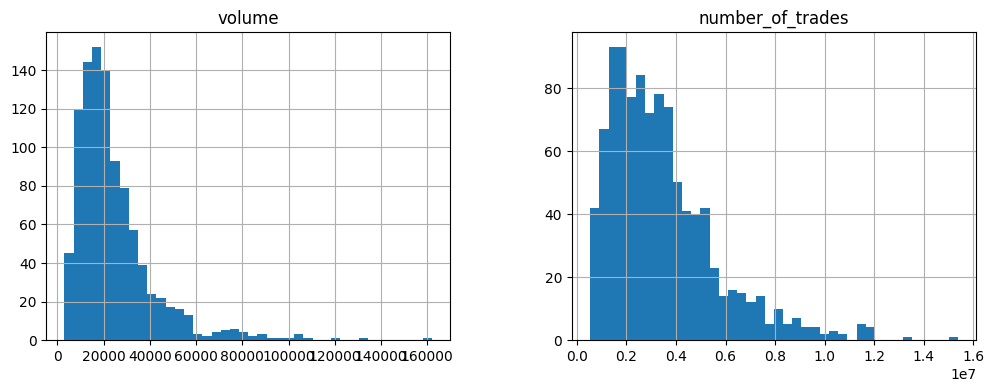

In [35]:
# The price level is not plotted as a histogram: it drifts over time, so it has no
# stable distribution. Volume and number of trades do.
df[['volume', 'number_of_trades']].hist(figsize=(12, 4), bins=40)

### Conclusions

In [36]:
# Printed from the data, so the text always matches the file on disk.
volume_skew = df['volume'].mean() / df['volume'].median() - 1

print('- {} daily bars from {} to {} (UTC), no missing values and no missing days.'.format(
    len(df), df.index.min().date(), df.index.max().date()))
print('- The close ranges from {:,.0f} to {:,.0f} USDT. A price level drifts over time, so the'.format(
    df['close'].min(), df['close'].max()))
print('  next notebooks work on returns, not on prices.')
print('- Volume is right-skewed: its mean is {:.0%} above its median, so a few days carry very large volume.'.format(
    volume_skew))

- 1000 daily bars from 2024-02-20 to 2026-11-15 (UTC), no missing values and no missing days.
- The close ranges from 50,744 to 124,659 USDT. A price level drifts over time, so the
  next notebooks work on returns, not on prices.
- Volume is right-skewed: its mean is 21% above its median, so a few days carry very large volume.
